In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tifffile
import fastplotlib as fpl
from clustering.utils import generate_data, SpaceTimeSVD, ClusteringCPQR

To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

No windowing system present. Using surfaceless platform
No config found!
No config found!


Available devices:
✅ (default) | Tesla V100-SXM2-32GB | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 16.0.6, 256 bits) | CPU | Vulkan | Mesa 24.0.0-devel (git-3ca1f35cbf) (LLVM 16.0.6)
❗ | Tesla V100-SXM2-32GB/PCIe/SSE2 | Unknown | OpenGL | 


In [2]:
import scipy

In [3]:
from matplotlib import pyplot as plt

In [4]:
%matplotlib inline

In [5]:
path = "/mnt/home/kkolar/data/jason/jason/M19/D05/M19D5_MC.tif"
movie = tifffile.imread(path)[:10_000, 128:-138:2, 138:-132:2].astype(np.float32)

In [6]:
movie_mean = movie.mean(axis=0)

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:21: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterWgpuCanvas()
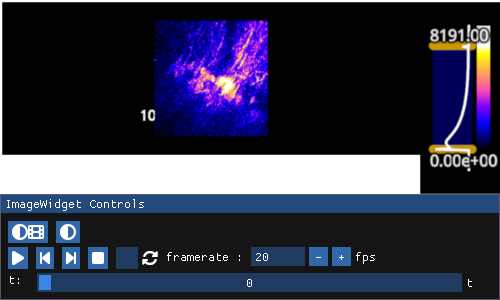

In [7]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2")
iw_movie.show()

In [8]:
iw_movie.window_funcs = {"t": (np.mean, 33)}

In [9]:
v1 = np.load("./v_ss-2.npy")

In [10]:
xdim, ydim = 123, 121
B = v1[0].reshape(123 * 121, 123 * 121)
B = np.abs((B + B.T) / 2)

B.shape

(14883, 14883)

RFBOutputContext()

JupyterWgpuCanvas()
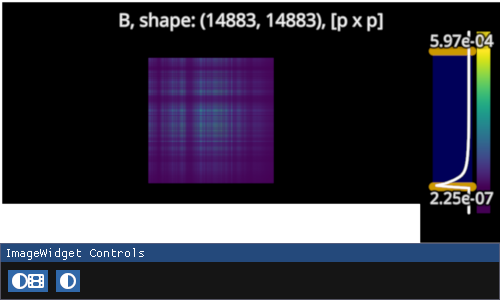

In [11]:
iw_adj = fpl.ImageWidget(
    B, 
    cmap="viridis",
    names=[f"B, shape: {B.shape}, [p x p]"]
)
iw_adj.show()

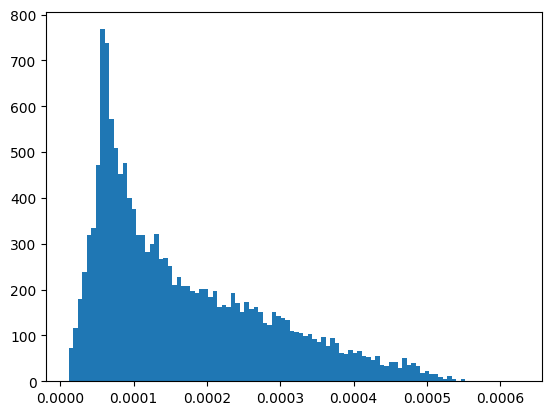

In [12]:
plt.hist(B.max(axis=1), bins=100)
plt.show()

In [13]:
np.argsort(B.sum(axis=0))

array([14766, 14767, 14768, ...,  8792,  8192,  8794])

In [14]:
np.sum(B[14766, :])

0.04641665180489722

In [15]:
np.sum(B[8794, :])

2.5013944978859315

In [16]:
from tqdm import tqdm

In [17]:
bg_image = np.zeros(xdim * ydim)
for i in tqdm(range(len(bg_image))):
    bg_image[i] = np.sum(B[i, :])

bg_image = bg_image.reshape((xdim, ydim))

100%|██████████████████████████████████████████████████████████████████████████████████| 14883/14883 [00:00<00:00, 55439.90it/s]


RFBOutputContext()

JupyterWgpuCanvas()
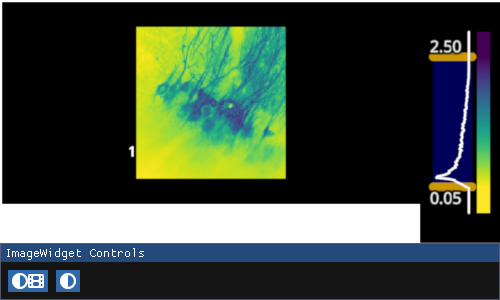

In [18]:
iw_bg = fpl.ImageWidget(bg_image, cmap="viridis_r")
iw_bg.show()

In [19]:
bg_threshold = 0.6

In [20]:
bg_ixs = B.sum(axis=1) < bg_threshold
bg_ixs

array([ True,  True,  True, ...,  True,  True,  True])

In [21]:
bg_ixs.sum()

8215

In [22]:
B2 = B[~bg_ixs][:, ~bg_ixs]

In [23]:
B2.shape

(6668, 6668)

In [103]:
_, _, pivots = scipy.linalg.qr(B2, pivoting=True)
evals, Qk = scipy.sparse.linalg.eigsh(B2, k=30)

In [104]:
Qk[:, 0]

array([-0.00785253, -0.01401375,  0.00805276, ..., -0.01370731,
       -0.00977608, -0.00916779])

In [105]:
new_ixs = np.where(B.sum(axis=1) >= bg_threshold)[0]
new_ixs

array([   40,    51,    53, ..., 13051, 13052, 13171])

In [106]:
pivots

array([5257, 5873, 3087, ..., 4481, 4659, 4386], dtype=int32)

In [107]:
mapped_pivots = new_ixs[pivots[:50]]
mapped_pivots

array([ 8794,  9981,  5985,  6188,  8677,  9389, 10606,  8875, 10509,
        6684, 10135,  8149,  6852, 10956,  4325,  7358,  9392,  8648,
        6338,  7725, 10121,  7081,  4950,   477,  7929,  8900,   798,
         351,  1865, 10613, 10517,  6733, 11571,  8903,  5134,  1853,
        1087,  5790, 10354,  5601,  7787,   235,   952,  4580,  8639,
         354,  5178,  8212,   908,  8701])

In [108]:
Qk.shape

(6668, 30)

In [109]:
from scipy.linalg import interpolative

In [110]:
Qk.T.shape

(30, 6668)

In [111]:
k = 30

In [112]:
max_k, ixs, proj = interpolative.interp_decomp(Qk.T[:k], eps_or_k=0.001)
max_k

30

In [113]:
ixs

array([5260, 6302, 4652, ..., 6665, 6666, 6667], dtype=int32)

In [114]:
ixs.shape

(6668,)

In [115]:
id_seeds = new_ixs[ixs[:k]]

In [116]:
id_seeds

array([ 8797, 10872,  7929, 10121,  9146,  8563,  8030,  7081,  6577,
       10741, 10230, 10271,  4950,  7192,  9033,  7090,  2587,  9119,
        6733,  6308, 11693,  9492,  4325,  6920,  6870,   116,  7062,
       10613,  4311,  4207])

In [117]:
row_ixs = np.floor_divide(id_seeds, ydim)
col_ixs = np.mod(id_seeds, ydim)

RFBOutputContext()

JupyterWgpuCanvas()
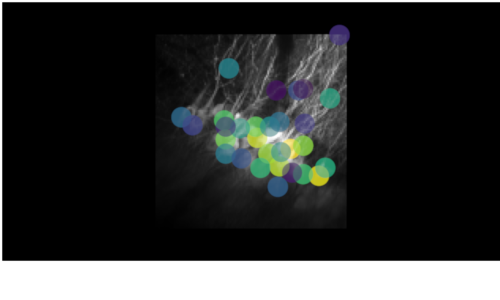

In [118]:
fig_basis = fpl.Figure()
fig_basis[0, 0].add_image(movie_mean, cmap="gray")
# fig_basis[0, 0].add_scatter(np.fliplr(np.argwhere(pivots_img > 1)), sizes=20, cmap="winter", alpha=1)
fig_basis[0, 0].add_scatter(np.column_stack([col_ixs, row_ixs]), sizes=20, cmap="viridis_r", alpha=0.7)
fig_basis.show()

In [119]:
proj.shape

(30, 6638)

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 1., ..., 0., 1., 0.],
        [0., 0., 1., ..., 1., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 5., ..., 0., 0., 0.],
        [0., 0., 4., ..., 0., 1., 0.]]),
 array([-0.68493527, -0.51414561, -0.34335594, -0.17256628, -0.00177661,
         0.16901305,  0.33980272,  0.51059238,  0.68138205,  0.85217171,
         1.02296138]),
 <a list of 1000 BarContainer objects>)

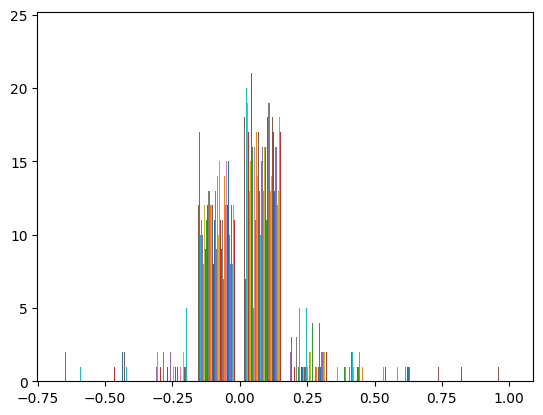

In [120]:
plt.hist(proj[:, :1000])

In [121]:
proj_ = proj.copy()
proj_[(proj_ > -0.5) & (proj_ < 0.5)] = 0

In [122]:
new_ixs[ixs]

array([ 8797, 10872,  7929, ..., 13051, 13052, 13171])

In [123]:
def images_from_proj(projection, k, new_indices, projection_indices):
    images = np.zeros((k, xdim * ydim))
    
    projection = np.hstack([np.eye(k), projection])

    indices = new_indices[projection_indices]

    for i in range(k):
        images[i, indices] = projection[i]

    return images.reshape((k, xdim, ydim))

In [124]:
proj_images = images_from_proj(proj_, 30, new_ixs, ixs)

RFBOutputContext()

JupyterWgpuCanvas()
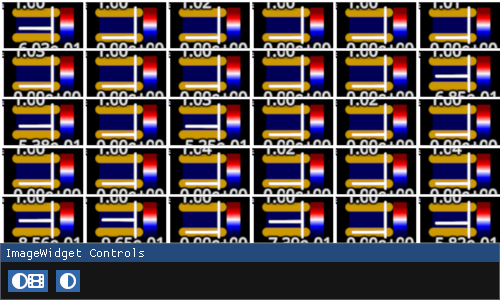

In [126]:
iw_proj_images = fpl.ImageWidget([p for p in proj_images[:30]], cmap="seismic")
iw_proj_images.show()

RFBOutputContext()

JupyterWgpuCanvas()
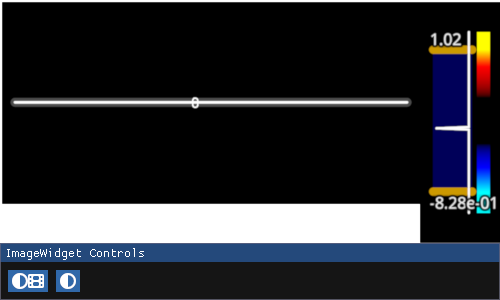

In [138]:
iw_proj = fpl.ImageWidget(proj_, cmap="RdYeBuCy")

ls_proj = iw_proj.managed_graphics[0].add_linear_selector(axis="y")

iw_proj.show()

In [139]:
proj_[proj_  < 0] = 0
proj_[proj_  > 0] = 1

RFBOutputContext()

JupyterWgpuCanvas()
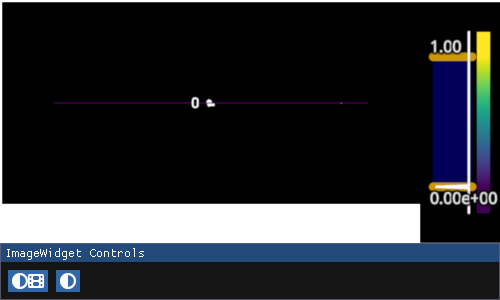

In [140]:
iw_proj = fpl.ImageWidget(proj_, cmap="viridis")
iw_proj.show()

(array([6.102e+03, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 5.300e+02,
        0.000e+00, 0.000e+00, 0.000e+00, 6.000e+00]),
 array([0. , 0.2, 0.4, 0.6, 0.8, 1. , 1.2, 1.4, 1.6, 1.8, 2. ]),
 <BarContainer object of 10 artists>)

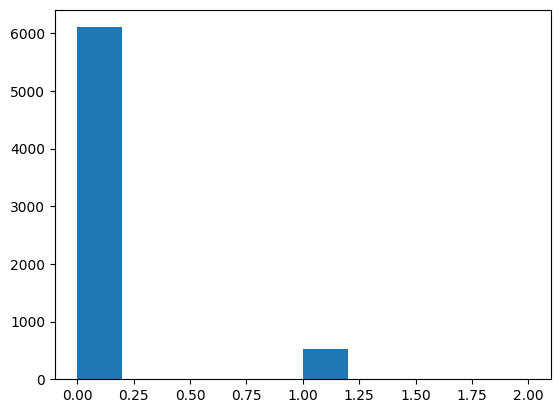

In [141]:
plt.hist(proj_.sum(axis=0))

In [142]:
ixs

array([  77, 5260, 6303, ..., 6665, 6666, 6667], dtype=int32)

In [143]:
proj.shape

(30, 6638)

In [144]:
labels_img = np.zeros((xdim * ydim))
labels_img.shape

(14883,)

In [145]:
mapped_id_all = new_ixs[ixs]
mapped_id_all.shape

(6668,)

In [146]:
mapped_id_all

array([  235,  8797, 10873, ..., 13051, 13052, 13171])

In [147]:
proj_[0].shape

(6638,)

In [148]:
proj_[0]

array([0., 0., 0., ..., 0., 0., 0.])

In [151]:
proj_labels = np.hstack([np.eye(30), proj_])
proj_labels.shape

(30, 6668)

In [152]:
proj_labels[0]

array([1., 0., 0., ..., 0., 0., 0.])

In [153]:
new_ixs[proj_labels[0] > 0]

array([  40,  114,  115,  355,  356, 2988, 5290])

In [154]:
for cluster_ix in range(30):
    labels_img[new_ixs[proj_labels[cluster_ix] > 0]] = cluster_ix

labels_img = labels_img.reshape((xdim, ydim))

RFBOutputContext()

JupyterWgpuCanvas()
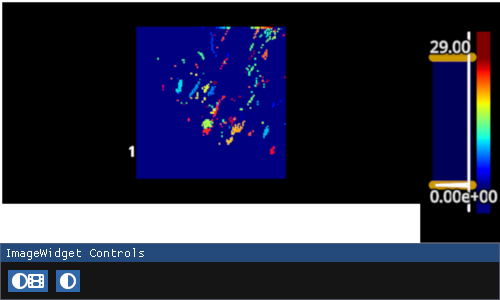

In [155]:
iw_labels = fpl.ImageWidget(labels_img, cmap="jet")
iw_labels.show()

In [282]:
labels_img

array([[ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ..., 28., 28., 28.],
       ...,
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.]])

RFBOutputContext()

JupyterWgpuCanvas()
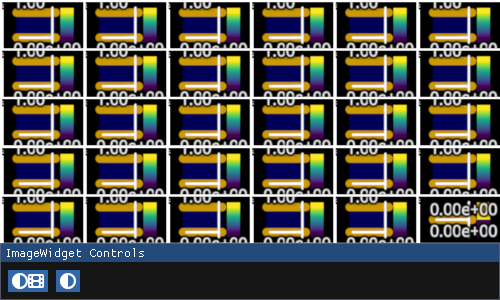

In [279]:
iw_labels_ind = fpl.ImageWidget([labels_img == i for i in range(1, k_id + 1)], cmap="viridis")
iw_labels_ind.show()

In [301]:
labels_img_alpha = np.zeros((xdim, ydim, 4))
labels_img_alpha[labels_img > 0, :-1] = [1., 0., 0.]

labels_img_alpha[labels_img > 0, -1] = 0.3

In [302]:
labels_img_alpha[:, :, -1].max()

0.3

In [305]:
labels_img == 1

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

In [308]:
from fastplotlib.utils import make_colors

In [310]:
colors = make_colors(30, "jet")

In [336]:
ixs.shape

(6668,)

In [337]:
proj_.shape

(30, 6638)

In [346]:
overlapping_pixels = new_ixs[np.hstack([np.zeros(k_id), (proj_.sum(axis=0) > 1)]) > 0]

overlap_pixels_img = np.zeros(xdim * ydim)
for n, i in tqdm(enumerate(overlapping_pixels)):
    overlap_pixels_img[i] = n

overlap_pixels_img = overlap_pixels_img.reshape((xdim, ydim))

347it [00:00, 1837655.92it/s]


RFBOutputContext()

JupyterWgpuCanvas()
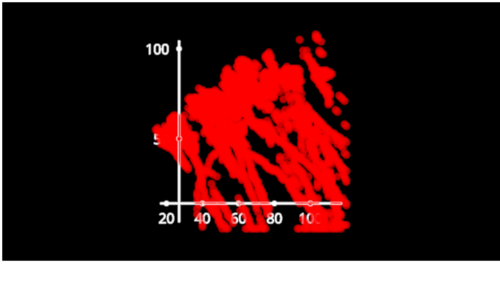

In [376]:
fig_alpha = fpl.Figure()
subplot = fig_alpha[0, 0]

for i in range(1, k_id):
    _img = np.zeros((xdim * ydim))
    _img[new_ixs[proj_labels[i] > 0]] = 1

    _img = _img.reshape((xdim, ydim))
    
    subplot.add_scatter(np.fliplr(np.argwhere(_img > 0)), sizes=7, colors="r", alpha=0.5)
    
fig_alpha.show()

In [380]:
for g in subplot.graphics:
    g.colors[:, -1] = 0.25

In [351]:
subplot.graphics[-1].sizes = 7

In [353]:
subplot.graphics[-1].colors = "w"

In [354]:
subplot.graphics[-1].alpha = 0.8